<a href="https://colab.research.google.com/github/nguyenkyvi/Machine_Learning/blob/main/Lab07_Accuracy_Metrics/Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Đọc dữ liệu (Lưu ý: Trên Colab, bạn cần đảm bảo đã tải tệp CSV lên thư mục phù hợp)
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình Lưới: ai cũng đoán là Lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, " f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      6.5             6           1             9       0
1      6.9             1           0             7       0
2      6.1             2           1             0       0
3      5.2             4           1            13       1
4      5.8             1           1            13       0

So sinh vien moi lop:
bo_hoc
0    1078
1     122
Ty le bo hoc: 0.102

Tap kiem tra: 300 ban, 31 ban bo hoc

Mo hinh luoi      accuracy 0.8967, tim ra 0 tren 31 ban bo hoc
Hoi quy logistic  accuracy 0.9100, tim ra 8 tren 31 ban bo hoc


In [19]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall    = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1        = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f})"
      f" = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                            target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
  Precision = 8 / (8 + 4) = 0.6667
  Recall    = 8 / (8 + 23) = 0.2581
  F1        = 2 x 0.6667 x 0.2581 / (0.6667 + 0.2581) = 0.3721

Tinh bang scikit-learn:
  Precision = 0.6667
  Recall    = 0.2581
  F1        = 0.3721

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9201    0.9851    0.9515       269
      bo hoc     0.6667    0.2581    0.3721        31

    accuracy                         0.9100       300
   macro avg     0.7934    0.6216    0.6618       300
weighted avg     0.8939    0.9100    0.8917       300



In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]      # xác suất bỏ học của từng bạn

print("Tap kiem tra, doi nguong")
print("nguong  so bao   TP FP FN   precision recall    F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}    {du.sum():4d}   {tp:3d} {fp:3d} {fn:3d}"
          f"   {precision_score(y_te, du):.4f}   "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
# Mỗi bạn trong tập học nhận xác suất từ một mô hình chưa từng thấy bạn ấy.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                           method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
      f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
      f" precision {precision_score(y_te, du):.4f},"
      f" recall {recall_score(y_te, du):.4f},"
      f" F1 {f1_score(y_te, du):.4f}")

Tap kiem tra, doi nguong
nguong  so bao   TP FP FN   precision recall    F1
  0.5      12     8   4  23   0.6667   0.2581  0.3721
  0.4      23    13  10  18   0.5652   0.4194  0.4815
  0.3      28    15  13  16   0.5357   0.4839  0.5085
  0.2      38    18  20  13   0.4737   0.5806  0.5217
  0.1      71    25  46   6   0.3521   0.8065  0.4902

Nguong cho F1 cao nhat tren tap hoc: 0.3 (F1 kiem dinh cheo 0.4914)
Tap kiem tra voi nguong 0.3: precision 0.5357, recall 0.4839, F1 0.5085


In [21]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"     {a:.4f}      {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                 KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(probability=True, random_state=0)),
}
print("Mo hinh          AUC     recall  F1 (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, p):.4f}  "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Duong ROC co 45 diem. Vai diem dau:
  bao dong nham   recall
     0.0000      0.0000
     0.0000      0.0323
     0.0000      0.0968
     0.0037      0.0968
     0.0037      0.1290
     0.0112      0.1290
AUC cua logistic = 0.9066

Mo hinh          AUC     recall  F1 (nguong 0.5)
  Logistic       0.9066  0.2581  0.3721
  Naive Bayes    0.8934  0.0968  0.1667
  KNN, k = 15    0.8393  0.0645  0.1212
  Cay sau 4      0.8212  0.0968  0.1765
  Rung 200 cay   0.8721  0.2258  0.3043
  SVM RBF        0.7413  0.0645  0.1176


In [22]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"     {a:.4f}      {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                 KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(probability=True, random_state=0)),
}
print("Mo hinh          AUC     recall  F1 (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, p):.4f}  "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Duong ROC co 45 diem. Vai diem dau:
  bao dong nham   recall
     0.0000      0.0000
     0.0000      0.0323
     0.0000      0.0968
     0.0037      0.0968
     0.0037      0.1290
     0.0112      0.1290
AUC cua logistic = 0.9066

Mo hinh          AUC     recall  F1 (nguong 0.5)
  Logistic       0.9066  0.2581  0.3721
  Naive Bayes    0.8934  0.0968  0.1667
  KNN, k = 15    0.8393  0.0645  0.1212
  Cay sau 4      0.8212  0.0968  0.1765
  Rung 200 cay   0.8721  0.2258  0.3043
  SVM RBF        0.7413  0.0645  0.1176


BÀi Tập

Bài 1

In [23]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def chia(a, b):
    """Chia an toan: mau so bang 0 thi tra ve 0.0 (giong zero_division=0)."""
    return a / b if b != 0 else 0.0

def danh_gia(y_that, y_doan):
    y_that, y_doan = np.asarray(y_that), np.asarray(y_doan)
    tp = int(np.sum((y_that == 1) & (y_doan == 1)))
    fp = int(np.sum((y_that == 0) & (y_doan == 1)))
    fn = int(np.sum((y_that == 1) & (y_doan == 0)))
    tn = int(np.sum((y_that == 0) & (y_doan == 0)))
    acc = chia(tp + tn, tp + fp + fn + tn)
    p = chia(tp, tp + fp)
    r = chia(tp, tp + fn)
    f1 = chia(2 * p * r, p + r)
    return acc, p, r, f1

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X, y = df.drop(columns="bo_hoc"), df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mo_hinh = {
    "Mo hinh luoi": DummyClassifier(strategy="most_frequent"),
    "Hoi quy logistic": make_pipeline(StandardScaler(), LogisticRegression()),
}
for ten, mh in mo_hinh.items():
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"== {ten}")
    print("  Ham tu viet : acc %.4f  precision %.4f  recall %.4f  F1 %.4f" % danh_gia(y_te, du))
    print("  scikit-learn: acc %.4f  precision %.4f  recall %.4f  F1 %.4f" % (
        accuracy_score(y_te, du),
        precision_score(y_te, du, zero_division=0),
        recall_score(y_te, du), f1_score(y_te, du, zero_division=0)))

== Mo hinh luoi
  Ham tu viet : acc 0.8967  precision 0.0000  recall 0.0000  F1 0.0000
  scikit-learn: acc 0.8967  precision 0.0000  recall 0.0000  F1 0.0000
== Hoi quy logistic
  Ham tu viet : acc 0.9100  precision 0.6667  recall 0.2581  F1 0.3721
  scikit-learn: acc 0.9100  precision 0.6667  recall 0.2581  F1 0.3721


BÀi 2

In [24]:
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
du = make_pipeline(StandardScaler(), SVC()).fit(X_tr, y_tr).predict(X_te)
print(classification_report(y_te, du, digits=4))

rec = recall_score(y_te, du, average=None)
pre = precision_score(y_te, du, average=None)
print("Chu so recall thap nhat   :", rec.argmin(), round(rec.min(), 4))
print("Chu so precision thap nhat:", pre.argmin(), round(pre.min(), 4))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    0.9773    0.9885        44
           3     0.9778    0.9565    0.9670        46
           4     0.9362    0.9778    0.9565        45
           5     1.0000    1.0000    1.0000        46
           6     0.9783    1.0000    0.9890        45
           7     0.9773    0.9556    0.9663        45
           8     0.9545    0.9767    0.9655        43
           9     0.9767    0.9333    0.9545        45

    accuracy                         0.9778       450
   macro avg     0.9779    0.9777    0.9777       450
weighted avg     0.9781    0.9778    0.9777       450

Chu so recall thap nhat   : 9 0.9333
Chu so precision thap nhat: 4 0.9362


Bài 3

In [25]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X, y = df.drop(columns="bo_hoc"), df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

lr = make_pipeline(StandardScaler(), LogisticRegression())
# Chon nguong CHI tren tap hoc
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.01, 0.96, 0.01), 2)
dat = [t for t in cac_nguong if recall_score(y_tr, (xs_hoc >= t).astype(int)) >= 0.8]
t_tot = max(dat)
print(f"Nguong lon nhat cho recall CV >= 0.8: {t_tot}"
      f" (recall CV = {recall_score(y_tr, (xs_hoc >= t_tot).astype(int)):.4f})")

# Mo tap kiem tra dung MOT LAN
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
du = (xs >= t_tot).astype(int)
r = recall_score(y_te, du)
print(f"Tap kiem tra: recall {r:.4f} ({'DAT' if r >= 0.8 else 'KHONG DAT'} 0.8),"
      f" precision {precision_score(y_te, du):.4f}, so ban bi bao {du.sum()} tren {len(du)}")

Nguong lon nhat cho recall CV >= 0.8: 0.09 (recall CV = 0.8022)
Tap kiem tra: recall 0.8387 (DAT 0.8), precision 0.3210, so ban bi bao 81 tren 300


Bài 4

Logistic: AUC = 0.9066
Rung 200 cay: AUC = 0.8721


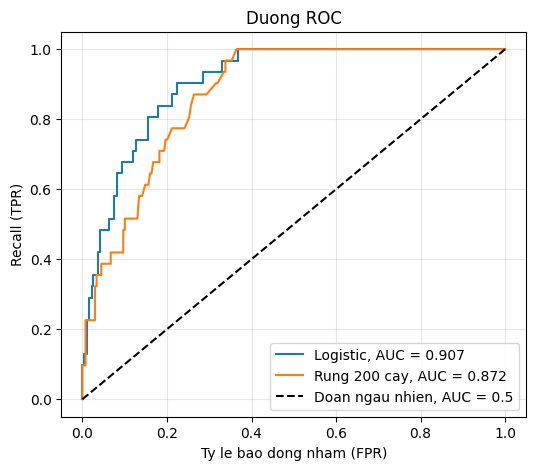

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X, y = df.drop(columns="bo_hoc"), df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mo_hinh = {"Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
           "Rung 200 cay": RandomForestClassifier(200, random_state=0)}
plt.figure(figsize=(6, 5))
for ten, mh in mo_hinh.items():
    p = mh.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    auc = roc_auc_score(y_te, p)
    print(f"{ten}: AUC = {auc:.4f}")
    plt.plot(fpr, tpr, label=f"{ten}, AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Doan ngau nhien, AUC = 0.5")
plt.xlabel("Ty le bao dong nham (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("Duong ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig("roc.png", dpi=150, bbox_inches="tight")
plt.show()

Bài 5

In [27]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X, y = df.drop(columns="bo_hoc"), df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

def tao(loai, cw):
    if loai == "Rung":
        return RandomForestClassifier(200, random_state=0, class_weight=cw)
    return make_pipeline(StandardScaler(), SVC(random_state=0, class_weight=cw))

print("Mo hinh  can bang   precision recall  F1")
for loai in ["Rung", "SVC"]:
    kq = {}
    for cw in [None, "balanced"]:
        du = tao(loai, cw).fit(X_tr, y_tr).predict(X_te)
        kq[cw] = (precision_score(y_te, du, zero_division=0), recall_score(y_te, du), f1_score(y_te, du))
        print(f"{loai:8s} {str(cw):10s} {kq[cw][0]:.4f}    {kq[cw][1]:.4f}  {kq[cw][2]:.4f}")
    print(f"   -> doi recall {kq['balanced'][1]-kq[None][1]:+.4f}, doi F1 {kq['balanced'][2]-kq[None][2]:+.4f}")

Mo hinh  can bang   precision recall  F1
Rung     None       0.5000    0.2258  0.3111
Rung     balanced   0.4667    0.2258  0.3043
   -> doi recall +0.0000, doi F1 -0.0068
SVC      None       1.0000    0.0323  0.0625
SVC      balanced   0.3023    0.8387  0.4444
   -> doi recall +0.8065, doi F1 +0.3819


BÀi 6

In [28]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/gia_nha.csv")
X, y = df.drop(columns="gia"), df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)
du = LinearRegression().fit(X_tr, y_tr).predict(X_te)

def ba_so(d):
    return (mean_absolute_error(y_te, d), np.sqrt(mean_squared_error(y_te, d)), r2_score(y_te, d))

truoc = ba_so(du)
du_hong = du.copy()
du_hong[0] += 5          # cong them 5 ty vao dung mot can
sau = ba_so(du_hong)
print(f"So can trong tap kiem tra: {len(y_te)}")
print("            MAE     RMSE    R2")
print("Truoc  %8.4f %8.4f %8.4f" % truoc)
print("Sau    %8.4f %8.4f %8.4f" % sau)
print("Tang gap: MAE x%.2f, RMSE x%.2f" % (sau[0]/truoc[0], sau[1]/truoc[1]))

So can trong tap kiem tra: 15
            MAE     RMSE    R2
Truoc    0.2185   0.2700   0.9759
Sau      0.5519   1.4433   0.3110
Tang gap: MAE x2.53, RMSE x5.35
